# House Prices (Kaggle) — modelo da competição e comparação de otimizadores

> Alan Hoffmann Dos Santos

Parte 1: limpeza, engenharia de atributos e modelos (árvores, lineares e ensemble) com validação cruzada 5-fold em RMSE do log.
Parte 2: comparação de otimizadores em uma rede neural (MLP) usando o dataset MPG.

Antes de rodar: `train.csv`, `test.csv` e `mpg_limpo.csv` ficam na pasta `DADOS` (definida na primeira célula de código).

In [1]:
import os, time, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import nnls
from scipy.stats import skew
from scipy.special import boxcox1p
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import Lasso, ElasticNet, RidgeCV
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone
import xgboost as xgb

# Pasta dos dados: a mesma do notebook (Trabalho_HousePrices/dados)
DADOS = Path(r'C:\Users\Alan\Desktop\HousePrices\Trabalho_HousePrices\dados')
if not DADOS.exists():
    DADOS = Path.cwd()

SEED = 42
random.seed(SEED); np.random.seed(SEED)


## 1. Carregamento e limpeza
Remove as 2 casas com mais de 4.000 pés² vendidas abaixo de US$ 300 mil. Estatísticas de preenchimento vêm só do treino.

In [ ]:
train = pd.read_csv(DADOS / 'train.csv', keep_default_na=False, na_values=['NA', ''])
test = pd.read_csv(DADOS / 'test.csv', keep_default_na=False, na_values=['NA', ''])

outliers = (train['GrLivArea'] > 4000) & (train['SalePrice'] < 300000)
train = train.loc[~outliers].reset_index(drop=True)
print('Treino após remover outliers:', train.shape, '| teste:', test.shape)

n_train = len(train)
test_id = test['Id']
y = np.log1p(train['SalePrice'].values)
dados = pd.concat([train.drop(columns='SalePrice'), test]).reset_index(drop=True).drop(columns='Id')
ref = dados.iloc[:n_train]

# Faltantes que significam "não possui"
nao_possui = ['PoolQC','MiscFeature','Alley','Fence','FireplaceQu','GarageType','GarageFinish','GarageQual',
              'GarageCond','BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2','MasVnrType']
for c in nao_possui:
    dados[c] = dados[c].fillna('None')
dados['Electrical'] = dados['Electrical'].fillna(ref['Electrical'].mode()[0])
for c in ['MSZoning','Functional','Utilities','Exterior1st','Exterior2nd','SaleType','KitchenQual']:
    dados[c] = dados[c].fillna(ref[c].mode()[0])
for c in dados.select_dtypes('number').columns:
    dados[c] = dados[c].fillna(ref[c].median())
for c in ['GarageYrBlt','MasVnrArea','LotFrontage']:
    dados[c] = dados[c].fillna(ref[c].median())
print('Faltantes restantes:', int(dados.isna().sum().sum()))


Treino após remover outliers: (1458, 81) | teste: (1459, 80)
Faltantes restantes: 0


## 2. Engenharia de atributos
Códigos viram categorias, qualidades viram 0–5 e algumas áreas e idades são combinadas.

In [4]:
for c in ['MSSubClass','MoSold','YrSold']:
    dados[c] = dados[c].astype(str)

qual = {'None':0,'Po':1,'Fa':2,'TA':3,'Gd':4,'Ex':5}
for c in ['ExterQual','ExterCond','BsmtQual','BsmtCond','HeatingQC','KitchenQual','FireplaceQu','GarageQual','GarageCond']:
    dados[c] = dados[c].map(qual).astype(int)

dados['TotalSF'] = dados['TotalBsmtSF'] + dados['1stFlrSF'] + dados['2ndFlrSF']
dados['QualTotSF'] = dados['OverallQual'] * dados['TotalSF']
dados['TotalBath'] = dados['FullBath'] + 0.5*dados['HalfBath'] + dados['BsmtFullBath'] + 0.5*dados['BsmtHalfBath']
dados['HouseAge'] = dados['YrSold'].astype(int) - dados['YearBuilt']
dados['RemodAge'] = dados['YrSold'].astype(int) - dados['YearRemodAdd']
dados['HasPool'] = (dados['PoolArea'] > 0).astype(int)


## 3. Matrizes para modelos
Árvores recebem só one-hot. Modelos lineares e a rede recebem também Box-Cox nas variáveis assimétricas.

In [5]:
X_arv = pd.get_dummies(dados).astype(float)
lin = dados.copy()
num = lin.select_dtypes('number').columns
sk = lin.iloc[:n_train][num].apply(lambda s: skew(s)).abs()
for c in sk[sk > 0.5].index:
    lin[c] = boxcox1p(lin[c].clip(lower=0), 0.15)
X_lin = pd.get_dummies(lin).astype(float)

X_arv_tr, X_arv_te = X_arv.iloc[:n_train].values, X_arv.iloc[n_train:].values
X_lin_tr, X_lin_te = X_lin.iloc[:n_train].values, X_lin.iloc[n_train:].values
print('Matriz árvores:', X_arv_tr.shape, '| matriz lineares:', X_lin_tr.shape)


Matriz árvores: (1458, 300) | matriz lineares: (1458, 300)


## 4. Validação cruzada
5 partes, RMSE do log, a mesma métrica do Kaggle.

In [6]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))

modelos = {
    'Árvore (GridSearch)': None,
    'Ridge': (make_pipeline(RobustScaler(), RidgeCV(alphas=np.logspace(-1, 2.5, 40))), 'lin'),
    'Lasso': (make_pipeline(RobustScaler(), Lasso(alpha=0.0005, max_iter=50000)), 'lin'),
    'ElasticNet': (make_pipeline(RobustScaler(), ElasticNet(alpha=0.0006, l1_ratio=0.8, max_iter=50000)), 'lin'),
    'Random Forest': (RandomForestRegressor(n_estimators=500, max_features=0.3, n_jobs=-1, random_state=SEED), 'arv'),
    'Extra Trees': (ExtraTreesRegressor(n_estimators=500, max_features=0.3, n_jobs=-1, random_state=SEED), 'arv'),
    'Gradient Boosting': (GradientBoostingRegressor(n_estimators=2000, learning_rate=0.02, max_depth=4,
                          max_features='sqrt', subsample=0.8, random_state=SEED), 'arv'),
    'XGBoost': (xgb.XGBRegressor(n_estimators=2000, learning_rate=0.02, max_depth=3, subsample=0.8,
                colsample_bytree=0.6, random_state=SEED, n_jobs=-1), 'arv'),
}

grade = {'max_depth': [3,4,5,6,8,10,None], 'min_samples_leaf': [1,3,5,10,20]}
busca = GridSearchCV(DecisionTreeRegressor(random_state=SEED), grade,
                     scoring='neg_root_mean_squared_error', cv=kf, n_jobs=-1).fit(X_arv_tr, y)
print('Árvore - melhores parâmetros:', busca.best_params_, '| RMSE:', round(-busca.best_score_, 4))
modelos['Árvore (GridSearch)'] = (busca.best_estimator_, 'arv')

oof, notas = {}, {}
for nome, (m, tipo) in modelos.items():
    Xtr = X_lin_tr if tipo == 'lin' else X_arv_tr
    t0 = time.time()
    oof[nome] = cross_val_predict(clone(m), Xtr, y, cv=kf)
    notas[nome] = rmse(oof[nome], y)
    print(f'{nome:22s} RMSE(log) = {notas[nome]:.4f}  ({time.time()-t0:.0f}s)')


Árvore - melhores parâmetros: {'max_depth': 10, 'min_samples_leaf': 10} | RMSE: 0.1678
Árvore (GridSearch)    RMSE(log) = 0.1680  (0s)
Ridge                  RMSE(log) = 0.1147  (5s)
Lasso                  RMSE(log) = 0.1119  (1s)
ElasticNet             RMSE(log) = 0.1120  (0s)
Random Forest          RMSE(log) = 0.1298  (13s)
Extra Trees            RMSE(log) = 0.1271  (15s)
Gradient Boosting      RMSE(log) = 0.1121  (17s)
XGBoost                RMSE(log) = 0.1152  (16s)


## 5. Ensemble com pesos NNLS
Os pesos saem das previsões out-of-fold, sem olhar o teste.

In [7]:
OOF = pd.DataFrame(oof)
w, _ = nnls(OOF.values, y)
w = w / w.sum()
pesos = pd.Series(w, index=OOF.columns).round(3)
print(pesos[pesos > 0].sort_values(ascending=False))
print('RMSE do ensemble (in-sample dos pesos):', round(rmse(OOF.values @ w, y), 4))


Lasso                0.491
Gradient Boosting    0.406
XGBoost              0.103
dtype: float64
RMSE do ensemble (in-sample dos pesos): 0.1082


## 6. Treino final e submissão
Treina cada modelo com todos os dados de treino e aplica os pesos no teste.

In [9]:
preds = {}
for nome, (m, tipo) in modelos.items():
    if pesos[nome] <= 0:
        continue
    Xtr = X_lin_tr if tipo == 'lin' else X_arv_tr
    Xte = X_lin_te if tipo == 'lin' else X_arv_te
    preds[nome] = clone(m).fit(Xtr, y).predict(Xte)

final_log = sum(pesos[n] * preds[n] for n in preds) / sum(pesos[n] for n in preds)
submissao = pd.DataFrame({'Id': test_id, 'SalePrice': np.expm1(final_log)})
submissao.to_csv(DADOS / 'submission.csv', index=False)
print(submissao.shape, '| vazios:', int(submissao.isna().sum().sum()), '| colunas:', list(submissao.columns))
submissao.head()


(1459, 2) | vazios: 0 | colunas: ['Id', 'SalePrice']


,Id,SalePrice
0,1461,123318.069835
1,1462,159151.602533
2,1463,186534.391209
3,1464,198792.235180
4,1465,189871.738040


## 7. Comparação de otimizadores (MLP no dataset MPG)
Mesma arquitetura, mesma semente, mesma divisão e early stopping. Só o otimizador muda.

In [2]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

mpg = pd.read_csv(DADOS / 'mpg_limpo.csv')
alvo = 'km_l'
entradas = [c for c in mpg.columns if c not in (alvo, 'name', 'origin')]
X = pd.get_dummies(mpg[entradas + ['origin']], columns=['origin']).astype(float).values
y_mpg = mpg[alvo].values.astype(float)

X_tr, X_te, y_tr, y_te = train_test_split(X, y_mpg, test_size=0.2, random_state=SEED)
esc = StandardScaler().fit(X_tr)
X_tr, X_te = esc.transform(X_tr).astype('float32'), esc.transform(X_te).astype('float32')

def criar_rede(seed=SEED):
    # No Keras 3, tf.random.set_seed não fixa os pesos iniciais; set_random_seed fixa
    # python, numpy, tensorflow e o gerador do Keras.
    tf.keras.utils.set_random_seed(seed)
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_tr.shape[1],)),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1),
    ])

In [ ]:
otimizadores = {
    'SGD': lambda: tf.keras.optimizers.SGD(learning_rate=0.01),
    'SGD+Momentum': lambda: tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    'RMSprop': lambda: tf.keras.optimizers.RMSprop(learning_rate=0.001),
    'Adagrad': lambda: tf.keras.optimizers.Adagrad(learning_rate=0.01),
    'Adadelta': lambda: tf.keras.optimizers.Adadelta(learning_rate=1.0),
    'Adam': lambda: tf.keras.optimizers.Adam(learning_rate=0.001),
    'AdamW': lambda: tf.keras.optimizers.AdamW(learning_rate=0.001),
    'Nadam': lambda: tf.keras.optimizers.Nadam(learning_rate=0.001),
}

resultados, curvas = [], {}
for nome, fabrica in otimizadores.items():
    net = criar_rede()
    net.compile(optimizer=fabrica(), loss='mse')
    t0 = time.time()
    hist = net.fit(X_tr, y_tr, validation_split=0.2, epochs=300, batch_size=32, verbose=0,
                   callbacks=[tf.keras.callbacks.EarlyStopping(patience=30, restore_best_weights=True)])
    pred = net.predict(X_te, verbose=0).ravel()
    curvas[nome] = hist.history
    resultados.append({'otimizador': nome, 'RMSE_teste': np.sqrt(mean_squared_error(y_te, pred)),
                       'MAE_teste': mean_absolute_error(y_te, pred), 'R2_teste': r2_score(y_te, pred),
                       'melhor_epoca': int(np.argmin(hist.history['val_loss']) + 1),
                       'tempo_s': round(time.time() - t0, 1)})

res = pd.DataFrame(resultados).sort_values('RMSE_teste')
res.to_csv(DADOS / 'comparacao_otimizadores_mpg.csv', index=False)
res.round(3)

fabrica = lambda: tf.keras.optimizers.SGD(learning_rate=0.001, momentum=0.9)
net = criar_rede()
net.compile(optimizer=fabrica(), loss='mse')
hist = net.fit(X_tr, y_tr, validation_split=0.2, epochs=300, batch_size=32, verbose=0,
               callbacks=[tf.keras.callbacks.EarlyStopping(patience=30, restore_best_weights=True)])
pred = net.predict(X_te, verbose=0).ravel()
print('RMSE:', np.sqrt(mean_squared_error(y_te, pred)), '| melhor época:', int(np.argmin(hist.history['val_loss']) + 1))

In [20]:
resultados2, curvas2 = [], {}
for nome, fabrica in {
    'SGD': lambda: tf.keras.optimizers.SGD(learning_rate=0.001),
    'SGD+Momentum': lambda: tf.keras.optimizers.SGD(learning_rate=0.001, momentum=0.9),
    'RMSprop': lambda: tf.keras.optimizers.RMSprop(learning_rate=0.001),
    'Adagrad': lambda: tf.keras.optimizers.Adagrad(learning_rate=0.001),
    'Adadelta': lambda: tf.keras.optimizers.Adadelta(learning_rate=0.001),
    'Adam': lambda: tf.keras.optimizers.Adam(learning_rate=0.001),
    'AdamW': lambda: tf.keras.optimizers.AdamW(learning_rate=0.001),
    'Nadam': lambda: tf.keras.optimizers.Nadam(learning_rate=0.001),
}.items():
    net = criar_rede()
    net.compile(optimizer=fabrica(), loss='mse')
    t0 = time.time()
    hist = net.fit(X_tr, y_tr, validation_split=0.2, epochs=300, batch_size=32, verbose=0,
                   callbacks=[tf.keras.callbacks.EarlyStopping(patience=30, restore_best_weights=True)])
    pred = net.predict(X_te, verbose=0).ravel()
    curvas2[nome] = hist.history
    resultados2.append({'otimizador': nome, 'RMSE_teste': np.sqrt(mean_squared_error(y_te, pred)),
                        'MAE_teste': mean_absolute_error(y_te, pred), 'R2_teste': r2_score(y_te, pred),
                        'melhor_epoca': int(np.argmin(hist.history['val_loss']) + 1),
                        'tempo_s': round(time.time() - t0, 1)})

res2 = pd.DataFrame(resultados2).sort_values('RMSE_teste')
res2.to_csv(DADOS / 'comparacao_otimizadores_mpg_lr001.csv', index=False)
res2.round(3)

,otimizador,RMSE_teste,MAE_teste,R2_teste,melhor_epoca,tempo_s
7,Nadam,0.985,0.723,0.895,212,26.1
1,SGD+Momentum,1.021,0.749,0.887,117,15.0
0,SGD,1.028,0.740,0.886,299,36.3
5,Adam,1.031,0.743,0.885,228,26.2
6,AdamW,1.066,0.770,0.877,297,30.9
2,RMSprop,1.071,0.762,0.876,110,14.6
3,Adagrad,2.217,1.712,0.467,300,30.5
4,Adadelta,9.623,9.121,-9.039,300,30.6


## 8. Gráfico das curvas de perda

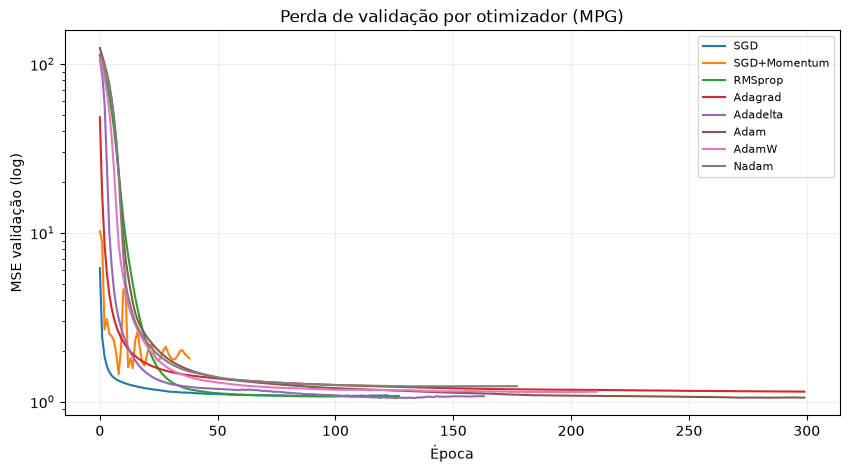

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
for nome, h in curvas.items():
    ax.plot(h['val_loss'], label=nome)
ax.set_yscale('log'); ax.set_xlabel('Época'); ax.set_ylabel('MSE validação (log)')
ax.set_title('Perda de validação por otimizador (MPG)'); ax.legend(fontsize=8); ax.grid(alpha=0.2)
plt.show()


## 9. Robustez: 3 sementes com as taxas escolhidas
Cada otimizador usa a taxa que funcionou melhor nas rodadas anteriores: 0,001 para SGD, SGD+Momentum, RMSprop, Adam, AdamW e Nadam; 0,01 para Adagrad; 1,0 para Adadelta.
A divisão treino/teste continua fixa (`random_state=SEED`); só a semente da rede muda (pesos iniciais e embaralhamento dos lotes). São 8 otimizadores × 3 sementes = 24 treinos (~10 a 15 min).

In [3]:
taxas = {'SGD': 0.001, 'SGD+Momentum': 0.001, 'RMSprop': 0.001, 'Adagrad': 0.01,
         'Adadelta': 1.0, 'Adam': 0.001, 'AdamW': 0.001, 'Nadam': 0.001}
fabricas = {
    'SGD': lambda lr: tf.keras.optimizers.SGD(learning_rate=lr),
    'SGD+Momentum': lambda lr: tf.keras.optimizers.SGD(learning_rate=lr, momentum=0.9),
    'RMSprop': lambda lr: tf.keras.optimizers.RMSprop(learning_rate=lr),
    'Adagrad': lambda lr: tf.keras.optimizers.Adagrad(learning_rate=lr),
    'Adadelta': lambda lr: tf.keras.optimizers.Adadelta(learning_rate=lr),
    'Adam': lambda lr: tf.keras.optimizers.Adam(learning_rate=lr),
    'AdamW': lambda lr: tf.keras.optimizers.AdamW(learning_rate=lr),
    'Nadam': lambda lr: tf.keras.optimizers.Nadam(learning_rate=lr),
}
SEMENTES = [42, 7, 2024]

brutos = []
for seed in SEMENTES:
    for nome, lr in taxas.items():
        net = criar_rede(seed)
        net.compile(optimizer=fabricas[nome](lr), loss='mse')
        t0 = time.time()
        hist = net.fit(X_tr, y_tr, validation_split=0.2, epochs=300, batch_size=32, verbose=0,
                       callbacks=[tf.keras.callbacks.EarlyStopping(patience=30, restore_best_weights=True)])
        pred = net.predict(X_te, verbose=0).ravel()
        brutos.append({'otimizador': nome, 'taxa': lr, 'semente': seed,
                       'RMSE_teste': np.sqrt(mean_squared_error(y_te, pred)), 'R2_teste': r2_score(y_te, pred),
                       'melhor_epoca': int(np.argmin(hist.history['val_loss']) + 1),
                       'tempo_s': round(time.time() - t0, 1)})
        print(f"semente {seed:>4} | {nome:<13} | RMSE {brutos[-1]['RMSE_teste']:.3f} | {brutos[-1]['tempo_s']} s")

brutos = pd.DataFrame(brutos)
brutos.to_csv(DADOS / 'otimizadores_sementes_brutos.csv', index=False)
print(brutos.shape)

semente   42 | SGD           | RMSE 1.051 | 41.0 s


semente   42 | SGD+Momentum  | RMSE 1.036 | 20.8 s


semente   42 | RMSprop       | RMSE 1.067 | 31.9 s


semente   42 | Adagrad       | RMSE 1.060 | 101.2 s


semente   42 | Adadelta      | RMSE 1.119 | 34.0 s


semente   42 | Adam          | RMSE 1.045 | 28.8 s


... (14 outputs left out)

semente 2024 | Adadelta      | RMSE 1.080 | 28.1 s


semente 2024 | Adam          | RMSE 1.067 | 59.1 s


semente 2024 | AdamW         | RMSE 1.065 | 62.1 s


semente 2024 | Nadam         | RMSE 1.056 | 58.9 s
(24, 7)


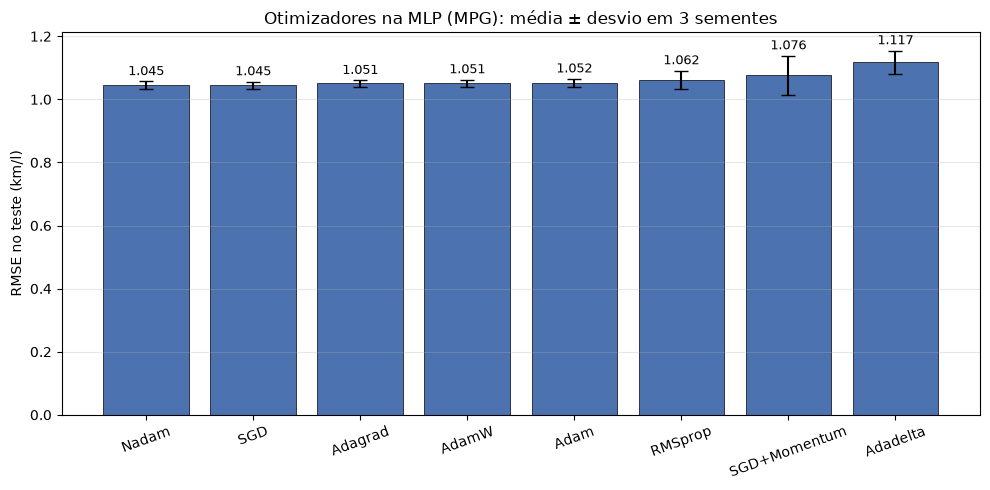

,otimizador,taxa,RMSE_media,RMSE_desvio,RMSE_min,RMSE_max,R2_media,epoca_media,tempo_media
0,Nadam,0.001,1.045,0.012,1.032,1.056,0.882,206.667,47.467
1,SGD,0.001,1.045,0.011,1.032,1.053,0.882,297.000,51.767
2,Adagrad,0.010,1.051,0.010,1.040,1.060,0.880,275.667,79.000
3,AdamW,0.001,1.051,0.012,1.043,1.065,0.880,218.667,43.733
4,Adam,0.001,1.052,0.013,1.044,1.067,0.880,218.667,45.200
5,RMSprop,0.001,1.062,0.030,1.030,1.088,0.878,107.000,30.167
6,SGD+Momentum,0.001,1.076,0.063,1.036,1.148,0.874,27.000,13.467
7,Adadelta,1.000,1.117,0.037,1.080,1.154,0.865,148.000,41.233


In [4]:
resumo = (brutos.groupby('otimizador')
          .agg(taxa=('taxa', 'first'),
               RMSE_media=('RMSE_teste', 'mean'), RMSE_desvio=('RMSE_teste', 'std'),
               RMSE_min=('RMSE_teste', 'min'), RMSE_max=('RMSE_teste', 'max'),
               R2_media=('R2_teste', 'mean'), R2_desvio=('R2_teste', 'std'),
               R2_min=('R2_teste', 'min'), R2_max=('R2_teste', 'max'),
               epoca_media=('melhor_epoca', 'mean'), epoca_desvio=('melhor_epoca', 'std'),
               epoca_min=('melhor_epoca', 'min'), epoca_max=('melhor_epoca', 'max'),
               tempo_media=('tempo_s', 'mean'), tempo_desvio=('tempo_s', 'std'),
               tempo_min=('tempo_s', 'min'), tempo_max=('tempo_s', 'max'))
          .sort_values('RMSE_media').reset_index())
resumo.to_csv(DADOS / 'otimizadores_resumo.csv', index=False)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(resumo['otimizador'], resumo['RMSE_media'], yerr=resumo['RMSE_desvio'], capsize=5,
       color='#4C72B0', edgecolor='black', linewidth=0.5)
for i, (m, d) in enumerate(zip(resumo['RMSE_media'], resumo['RMSE_desvio'])):
    ax.text(i, m + d + 0.02, f'{m:.3f}', ha='center', fontsize=9)
ax.set_ylabel('RMSE no teste (km/l)')
ax.set_title('Otimizadores na MLP (MPG): média ± desvio em 3 sementes')
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(DADOS / 'otimizadores_comparacao.png', dpi=150)
plt.show()

resumo[['otimizador', 'taxa', 'RMSE_media', 'RMSE_desvio', 'RMSE_min', 'RMSE_max',
        'R2_media', 'epoca_media', 'tempo_media']].round(3)